# 여행 계획 에이전트 (A2A)

https://github.com/a2aproject/a2a-samples/tree/main/samples/python/agents/travel_planner_agent



a2a-sdk **1.0** 기준으로 여행 계획 에이전트 서버를 띄우고, 클라이언트와 LangChain 툴로 연결하는 예제입니다.

- 서버 포트: `10001`
- 에이전트 카드 경로: `/.well-known/agent-card.json`


# 세팅


In [ ]:
! pip install -U "a2a-sdk" langchain-openai python-dotenv
! uv pip install --upgrade "protobuf>=5.29,<7"

In [1]:
from dotenv import load_dotenv

# .env 파일의 OPENAI_API_KEY를 환경변수로 로드
load_dotenv()

True

# A2A 서버


## 서버 코드 저장

아래 셀을 실행하면 `travel_server.py` 파일이 생성됩니다.


In [ ]:
%%writefile travel_server.py
# 실행: python travel_server.py
import os
from collections.abc import AsyncGenerator

import uvicorn
from a2a.helpers import (
    get_message_text,
    new_task_from_user_message,
    new_text_artifact_update_event,
    new_text_status_update_event,
)
from a2a.server.agent_execution import AgentExecutor, RequestContext
from a2a.server.events import EventQueue
from a2a.server.request_handlers import DefaultRequestHandler
from a2a.server.routes import create_agent_card_routes, create_jsonrpc_routes
from a2a.server.tasks import InMemoryTaskStore
from a2a.types import AgentCapabilities, AgentCard, AgentInterface, AgentSkill, TaskState
from dotenv import load_dotenv
from langchain_core.messages import HumanMessage, SystemMessage
from langchain_openai import ChatOpenAI
from starlette.applications import Starlette

load_dotenv()  # .env의 OPENAI_API_KEY 등을 환경변수로 로드

PORT = 10001

SYSTEM_PROMPT = """당신은 여행 일정 계획, 여행지 정보, 여행 추천을 전문으로 하는 여행 어시스턴트입니다.
- 계절, 예산, 이동 동선을 고려해 구체적이고 실행 가능한 조언을 할 것
- 명소 간 이동 시간을 반영한 현실적인 일자별 계획을 세울 것
- 대략적인 시간, 이동 방법, 현지 음식 중심의 식사 장소를 함께 적을 것
항상 한국어로 답변하고, 확실하지 않은 정보는 확실하지 않다고 밝히세요."""


class TravelPlannerAgent:
    """LLM 호출만 담당하는 에이전트 로직"""

    def __init__(self):
        # 환경변수에서 모델명과 API 키를 읽어 모델 객체 생성
        self.model = ChatOpenAI(
            model=os.getenv("MODEL_NAME", "gpt-5-mini"),
            api_key=os.getenv("OPENAI_API_KEY"),
        )

    async def stream(self, query: str) -> AsyncGenerator[str, None]:
        """모델 응답을 텍스트 조각 단위로 하나씩 넘겨줌"""
        messages = [SystemMessage(content=SYSTEM_PROMPT), HumanMessage(content=query)]
        async for chunk in self.model.astream(messages):
            if chunk.content:  # 빈 조각은 건너뜀
                yield chunk.content


class TravelPlannerAgentExecutor(AgentExecutor):
    """A2A 프로토콜과 에이전트 로직을 연결하는 실행기"""

    def __init__(self):
        self.agent = TravelPlannerAgent()

    async def execute(self, context: RequestContext, event_queue: EventQueue) -> None:
        # 진행 중인 Task가 없으면 사용자 메시지로 새 Task 생성
        task = context.current_task or new_task_from_user_message(context.message)
        # v1.0 규칙: Task 객체를 반드시 첫 이벤트로 큐에 올림
        await event_queue.enqueue_event(task)

        async def status(state, text):
            # 태스크 상태 갱신 이벤트를 큐에 올리는 내부 헬퍼
            await event_queue.enqueue_event(
                new_text_status_update_event(
                    task_id=task.id, context_id=task.context_id, state=state, text=text
                )
            )

        await status(TaskState.TASK_STATE_WORKING, "여행 계획을 생성하는 중입니다...")
        try:
            # 사용자 메시지에서 텍스트만 추출해 모델에 전달
            query = get_message_text(context.message)
            # 응답 조각이 나올 때마다 아티팩트 갱신 이벤트로 전송
            async for text in self.agent.stream(query):
                await event_queue.enqueue_event(
                    new_text_artifact_update_event(
                        task_id=task.id,
                        context_id=task.context_id,
                        name="current_result",
                        text=text,
                    )
                )
            await status(TaskState.TASK_STATE_COMPLETED, "완료되었습니다.")
        except Exception as e:
            print(f"오류: {e!s}")
            await status(TaskState.TASK_STATE_FAILED, "요청 처리 중 오류가 발생했습니다.")

    async def cancel(self, context: RequestContext, event_queue: EventQueue) -> None:
        # 취소는 지원하지 않음
        raise NotImplementedError("Cancel is not supported.")


# 에이전트가 제공하는 기능 정의
skill = AgentSkill(
    id="travel_planner",
    name="여행 계획 에이전트",
    description="여행 일정과 여행지 정보를 제공한다.",
    tags=["여행", "일정 계획"],
    examples=["부산 2박 3일 일정 짜줘", "10월에 교토 가면 뭐가 좋아?"],
)

# 클라이언트가 접속 정보를 파악하는 데 쓰는 에이전트 카드
agent_card = AgentCard(
    name="여행 계획 에이전트",
    description="여행 일정 계획과 여행지 추천을 담당하는 A2A 에이전트",
    version="1.0.0",
    default_input_modes=["text/plain"],
    default_output_modes=["text/plain"],
    capabilities=AgentCapabilities(streaming=True),
    supported_interfaces=[
        AgentInterface(
            protocol_binding="JSONRPC",
            url=f"http://127.0.0.1:{PORT}",
            protocol_version="1.0",
        )
    ],
    skills=[skill],
)

# 요청 처리와 태스크 관리를 담당하는 핸들러 (v1.0에서 agent_card 필수)
request_handler = DefaultRequestHandler(
    agent_executor=TravelPlannerAgentExecutor(),
    task_store=InMemoryTaskStore(),
    agent_card=agent_card,
)

# 카드 조회용 라우트와 JSON-RPC 라우트를 조립해 Starlette 앱 생성
routes = [*create_agent_card_routes(agent_card), *create_jsonrpc_routes(request_handler, "/")]
app = Starlette(routes=routes)

if __name__ == "__main__":
    uvicorn.run(app, host="127.0.0.1", port=PORT)


## 서버 실행

**터미널에서 별도로 실행**합니다. 노트북 셀에서 실행하면 셀이 계속 점유됩니다.

```
python travel_server.py
```


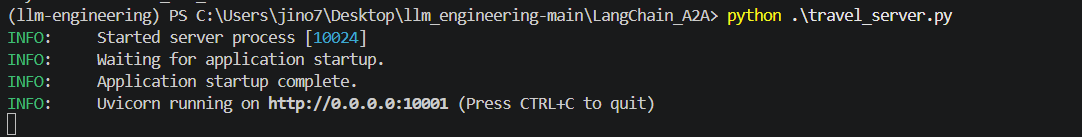

# A2A 클라이언트


In [2]:
# [셀 1] 임포트 및 설정
import httpx

from a2a.client import A2ACardResolver, ClientConfig, create_client
from a2a.helpers import display_agent_card, get_stream_response_text, new_text_message
from a2a.types import Role, SendMessageRequest

# 여행 계획 서버의 베이스 URL
BASE_URL = "http://127.0.0.1:10001"

# 이후 셀에서 재사용할 질의 문자열
TEXT_QUERY = "부산 2박 3일 일정 짜줘"

In [3]:
# [셀 2] 에이전트 카드 조회
# 카드 조회에 사용할 HTTP 클라이언트를 열고 기본 경로에서 카드를 가져옴
async with httpx.AsyncClient() as httpx_client:
    card = await A2ACardResolver(httpx_client=httpx_client, base_url=BASE_URL).get_agent_card()

# 카드 내용을 사람이 읽기 좋은 형태로 출력
display_agent_card(card)

                     AgentCard                      
--- General ---
Name        : 여행 계획 에이전트
Description : 여행 일정 계획과 여행지 추천을 담당하는 A2A 에이전트
Version     : 1.0.0

--- Interfaces ---
  [0] http://localhost:10001/  (JSONRPC)

--- Capabilities ---
Streaming           : True
Push notifications  : False
Extended agent card : False

--- I/O Modes ---
Input  : text/plain
Output : text/plain

--- Skills ---
----------------------------------------------------
  ID          : travel_planner
  Name        : 여행 계획 에이전트
  Description : 여행 일정과 여행지 정보를 제공하는 에이전트
  Tags        : 여행, 일정 계획, travel planner
  Example     : 부산 2박 3일 일정 짜줘
  Example     : 10월에 교토 가면 뭐가 좋아?


In [5]:
# [셀 3] 스트리밍 전송 (생성되는 텍스트를 실시간 출력)
import httpx

# 기본 5초로는 LLM 응답 대기에 부족하므로 읽기 타임아웃을 늘린 HTTP 클라이언트를 생성
http_client = httpx.AsyncClient(timeout=httpx.Timeout(300.0, connect=10.0))

# 위 HTTP 클라이언트를 사용하도록 설정에 주입
client = await create_client(
    agent=card,
    client_config=ClientConfig(streaming=True, httpx_client=http_client),
)
request = SendMessageRequest(message=new_text_message(TEXT_QUERY, role=Role.ROLE_USER))

# 응답 청크 중 아티팩트 갱신만 골라 텍스트를 이어 출력
async for chunk in client.send_message(request):
    if chunk.HasField("artifact_update"):
        print(get_stream_response_text(chunk), end="", flush=True)

# 전송 자원 해제
await client.close()
await http_client.aclose()

좋습니다 — 부산 2박 3일 기본 코스(대중교통 기준, 도보·버스·지하철 활용)를 준비해 드렸습니다. 숙소는 해운대(해변 중심) 또는 서면(교통·식사·밤문화 편리), 남포동(전통·관광 중심) 중 한 곳을 추천합니다. 출발/도착 시간이나 취향(해변·맛집·트레킹·쇼핑 등)을 알려주시면 일정 맞춤 수정해 드릴게요.

주의: 운영 시간이나 교통 상황은 변동될 수 있으니 출발 전 최신 정보(관광지 공식사이트/네이버/카카오맵)를 확인하세요.

=== 1일차 (도심·전통·야경) ===
가정: 오전 도착(부산역/김해공항) 기준

09:30 — 부산역/공항 → 숙소 체크인(수화물 보관 가능하면 맡기기)
- 이동: 공항리무진/공항철도/택시 또는 KTX 도착 시 지하철 이용
- 팁: T-money 교통카드 또는 모바일 교통카드 준비

10:30 — 자갈치시장 & 국제시장 (남포동)
- 소요시간: 1.5–2시간
- 할 것: 자갈치 2층 횟집에서 회(또는 포장), 국제시장 골목 음식(오뎅, 씨앗호떡 등)
- 이동: 도보

12:30 — BIFF 광장 & 광복로 거리
- 소요시간: 1시간 (사진·거리 음식·쇼핑)
- 추천 간식: 씨앗호떡, 통닭, 길거리 어묵
- 팁: 가게별 위생·리뷰 확인

14:00 — 감천문화마을 (알록달록 벽화 마을)
- 이동: 버스(남포동에서 10–20분) 또는 택시 약 10분
- 소요시간: 1.5–2시간 (골목 산책, 포토스팟)
- 추천: 골목 카페에서 쉬기

16:30 — 용두산공원 / 부산타워(선택)
- 소요시간: 1시간
- 전망대·소소한 기념품 샵

18:30 — 저녁: 광안리(광안대교 야경)
- 이동: 지하철 또는 버스(남포동→광안리 25–35분)
- 추천 식사: 해산물, 회, 해물탕 또는 광안리 해변 근처 바/카페
- 야경 추천 포인트: 광안리 해변 산책로, 광안대교 라이트업

21:30 — 야간: 광안리 바/카페 또는 해변 산책 후 숙소 귀환

=== 2일차 (해운대·바다·사찰) ===
08:00 — 해운대 해변 산책 & 조식 카페
- 이동: 지하

---


## 최소 코드


In [8]:
import httpx

from a2a.client import A2ACardResolver, ClientConfig, create_client
from a2a.helpers import get_stream_response_text, new_text_message
from a2a.types import Role, SendMessageRequest

# 기본 5초로는 LLM 생성 대기를 못 버티므로 타임아웃을 늘린 HTTP 클라이언트를 하나 만들어 공유
async with httpx.AsyncClient(timeout=600.0) as hc:
    # 서버에서 에이전트 카드를 가져옴 (접속 endpoint와 프로토콜 정보 포함)
    card = await A2ACardResolver(httpx_client=hc, base_url="http://127.0.0.1:10001").get_agent_card()

    # 같은 HTTP 클라이언트를 주입해 통신 클라이언트를 생성
    client = await create_client(
        agent=card,
        client_config=ClientConfig(streaming=True, httpx_client=hc),
    )

    # 메시지를 보내고 아티팩트 갱신 청크의 텍스트만 이어서 출력
    request = SendMessageRequest(message=new_text_message("교토 3일 코스 알려줘", role=Role.ROLE_USER))
    async for chunk in client.send_message(request):
        if chunk.HasField("artifact_update"):
            print(get_stream_response_text(chunk), end="")

    await client.close()

좋습니다 — 교토 3일 표준 코스(처음 방문하는 분들 기준, 숙소를 교토역/가와라마치(시내) 인근에 잡았다는 가정)입니다. 계절·이동수단·체력에 따라 조정해야 하니, 원하시면 취향(사찰 위주/자연·사진/음식·예산 등)과 숙소 위치 알려주세요.

기본 팁(먼저 읽어주세요)
- 교통: ICOCA/Suica 같은 IC카드가 편리. 버스는 노선이 복잡하고 정체가 있어 장거리 이동엔 전철(또는 JR)이 더 빠름. 관광지 주변은 도보 이동이 많음.
- 시간: 인기 명소(후시미 이나리, 아라시야마 대나무숲 등)는 이른 아침(7시 전후) 혹은 늦은 오후가 비교적 한적합니다.
- 예절: 사찰에선 조용히, 사진 금지 표지 확인, 신사참배 시 예절(두번 인사 등)을 지키세요.
- 현금: 소규모 가게는 카드 미사용인 경우가 있으니 현금 조금 준비.
- 운영시간/이동시간은 변동 가능하니 출발 전 확인 권장.

1일차 — 히가시야마 & 기요미즈·길거리 풍경 (도보 중심)
- 08:00 교토역 출발 → 후시미 이나리 타이샤(이른 방문 권장)
  - 이동: JR 나라선으로 약 5–10분(Inari역 하차), 도보 2–5분
  - 소요: 1.5시간(개인 페이스에 따라 토리이 완주 여부 결정)
  - 팁: 전체 산행(약 2–3시간)이 가능하나 처음엔 주구간(입구~중간)만 추천
- 10:30 히가시야마 지역(야사카 신사 → 니넨자카·산넨자카) 산책
  - 이동: 후시미 이나리에서 전철/버스로 이동 후 도보(약 20–30분 소요 예상)
  - 소요: 1.5–2시간(전통 거리와 상점가 구경)
  - 식사: 니넨자카 주변 오코노미야키/또는 규동 가게(또는 가벼운 교토 스위츠)
- 13:00 기요미즈데라 방문
  - 소요: 1–1.5시간(본당·토지 주변 산책 포함)
  - 팁: 전망대(기요미즈 무대)에서 경치 감상
- 15:00 기온 구경 및 찻집 체험(마차/게이샤 거리 산책)
  - 소요: 1–2시간(저녁에 게이샤 워치 가능)
  - 저녁: 폰토초 골목에서 가이세키(코스) 또는 이자카야 추천
- 저

# LangChain 에이전트와 연결


In [9]:
# [셀 1] 임포트 및 설정
import httpx
from a2a.client import ClientConfig, create_client
from a2a.helpers import get_stream_response_text, new_text_message
from a2a.types import Role, SendMessageRequest

from langchain.agents import create_agent
from langchain.tools import tool
from langchain_openai import ChatOpenAI

A2A_BASE_URL = "http://127.0.0.1:10001"

In [10]:
# [셀 2] A2A 서버 호출을 LangChain 툴로 래핑
@tool
async def travel_planner_agent(query: str) -> str:
    """원격 A2A 여행 계획 에이전트에게 질문을 보내고 답변 텍스트를 받아온다. 여행 일정이나 여행지 추천이 필요할 때 사용한다."""
    # 툴 호출 1회 동안만 유지되는 HTTP 클라이언트를 생성
    async with httpx.AsyncClient(timeout=120.0) as http_client:
        # 베이스 URL의 AgentCard를 조회해 그에 맞는 transport로 클라이언트를 생성
        client = await create_client(
            agent=A2A_BASE_URL,
            client_config=ClientConfig(streaming=True, httpx_client=http_client),
        )
        request = SendMessageRequest(message=new_text_message(query, role=Role.ROLE_USER))
        # 아티팩트 갱신 청크에서만 텍스트를 모음
        texts = [
            get_stream_response_text(r)
            async for r in client.send_message(request)
            if r.HasField("artifact_update")
        ]
    # 빈 문자열을 제외하고 이어 붙여 반환
    return "".join(filter(None, texts))

In [11]:
# [셀 3] 툴 단독 동작 확인 (에이전트 없이 A2A 연결만 검증)
print(await travel_planner_agent.ainvoke({"query": "부산 2박 3일 일정 짜줘"}))

좋습니다. 부산 2박 3일(주요 명소 + 현지 음식 + 실용 팁 포함) 기본 일정안을 만들어 드립니다. 도착/출발 시간, 예산, 선호(해변/먹방/카페/자연/쇼핑 등)를 알려주시면 맞춤 수정해 드릴게요.

기본 가정
- 출발지 → 부산 도착은 첫날 오전~오후, 마지막 날 저녁 이전 출발 가능으로 가정
- 이동은 대중교통(지하철·버스) + 필요 시 택시 활용
- 숙소는 위치 편의성 고려해 Haeundae / Seomyeon / Nampo 중 선택(아래에 추천) 가능

준비물 & 실용 팁
- 교통카드(T-money 또는 캐시비) 준비: 편의점·지하철 충전 가능
- 네이버지도/카카오맵 추천(버스·도보·실시간 도착 정보 확인)
- 계절별: 여름(수영복/모래/자외선 차단제), 겨울(바람·보온), 우천 시 실내 대체 코스 참고
- 주말/성수기엔 해변·관광지가 붐빔 → 오전 일찍 방문 권장
- 현금 소액(포장마차/시장), 휴대폰 충전기/보조배터리 필수
- 버스 번호·시간은 변경 가능하니 현장 확인 필요(확실하지 않은 정보는 현장 확인 권장)

일정안(권장 이동수단·예상 소요 포함)

1일차 — 항구·감성거리 중심 (Nampo/BIFF 지역 숙소 추천)
- 10:00 도착 → 숙소에 짐 보관(체크인 전이라면 수하물 보관)
- 11:00 Gamcheon Culture Village (감천문화마을)
  - 체류 1.5~2시간: 골목 산책, 포토스팟, 골목카페
  - 이동: 택시 약 15~20분(대중교통 연결도 가능하지만 택시가 시간 절약)
- 13:00 점심: 국제시장/BIFF 거리에서 분식·시장 음식
  - 추천: 씨앗호떡, 어묵, 떡볶이 등 길거리 음식
- 14:30 Jagalchi Market (자갈치시장) + BIFF광장(도보 이동)
  - 해산물 시식/식사(회, 노점 해산물 등). 1~1.5시간
  - 팁: 횟집 이용 시 가격 흥정·포장 선택지 확인, 초장·밑반찬 포함 여부 확인
- 16:30 Yongdusan Park & Busan Tower
  - 전망대(희망 시)를

In [13]:
# [셀 4] LangChain 에이전트 구성
llm = ChatOpenAI(model="gpt-5-mini", temperature=0)

agent = create_agent(
    model=llm,
    tools=[travel_planner_agent],
    system_prompt=(
        "너는 사용자의 요청을 처리하는 에이전트다. "
        "여행 일정이나 여행지 관련 요청은 travel_planner_agent 툴을 호출해 결과를 전달해라."
    ),
)

In [ ]:
# [셀 5] 에이전트 실행
result = await agent.ainvoke(
    {"messages": [{"role": "user", "content": "10월에 교토 3일 여행 갈 건데 일정 좀 짜줘"}]}
)



일정 잘 준비해 드렸습니다. 추가로 원하시면 숙소 예산·선호(전통·음식·사진·쇼핑 등)를 알려 주세요. 그에 맞춰 레스토랑·숙소 추천과 더 세부적인 시간표(열차·버스 번호 포함)로 맞춤 재작성해 드릴게요.


In [19]:
import pprint
pprint.pprint(result)

{'messages': [HumanMessage(content='10월에 교토 3일 여행 갈 건데 일정 좀 짜줘', additional_kwargs={}, response_metadata={}, id='dd574875-49a1-44fc-a1b8-c6279db1daa2'),
              AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 535, 'prompt_tokens': 217, 'total_tokens': 752, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 384, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cached_tokens': 0}}, 'model_provider': 'openai', 'model_name': 'gpt-5-mini-2025-08-07', 'system_fingerprint': None, 'id': 'chatcmpl-E4lmB4ltFHIPHOHGtIafr1jclhSdt', 'service_tier': 'default', 'finish_reason': 'tool_calls', 'logprobs': None}, id='lc_run--993b287d-9a05-49d4-9dea-60a2e344f4bb-0', tool_calls=[{'name': 'travel_planner_agent', 'args': {'query': 'Please provide a detailed 3-day Kyoto itinerary for travel in October. Include: suggested attractions for each morning/aftern

In [21]:
# 마지막 메시지가 최종 응답
print(result["messages"][-1].content)

일정 잘 준비해 드렸습니다. 추가로 원하시면 숙소 예산·선호(전통·음식·사진·쇼핑 등)를 알려 주세요. 그에 맞춰 레스토랑·숙소 추천과 더 세부적인 시간표(열차·버스 번호 포함)로 맞춤 재작성해 드릴게요.


In [20]:
# [셀 6] 스트리밍 출력으로 중간 단계 확인 (선택)
async for step in agent.astream(
    {"messages": [{"role": "user", "content": "제주도 1박 2일 코스 추천해줘"}]},
    stream_mode="values",
):
    step["messages"][-1].pretty_print()

================================ Human Message =================================

제주도 1박 2일 코스 추천해줘
================================== Ai Message ==================================
Tool Calls:
  travel_planner_agent (call_K0NSPSOkPfVnEMxx6Ddm2yMq)
 Call ID: call_K0NSPSOkPfVnEMxx6Ddm2yMq
  Args:
    query: 제주도 1박 2일 여행 코스 추천해줘. 출발과 종료는 제주공항 기준, 이동수단은 렌터카로 가정. 시간대별 일정(시간표), 추천 관광지, 식사 장소(지역 맛집 예시), 숙소 유형 추천(중급 호텔/펜션/게스트하우스), 소요시간과 이동거리(대략), 계절별(봄/여름/가을/겨울) 추천 포인트와 짧은 예산 가이드(저렴/중간/고급). 일반 여행자(특정 취향 미지정) 기준으로 3가지 스타일(자연 중심, 액티비티/체험 중심, 휴식/커플 로맨틱) 각각 하나씩 제안해줘.
================================= Tool Message =================================
Name: travel_planner_agent

아래는 제주공항 출발·도착, 렌터카 기준의 1박 2일 코스 3종 (자연 중심 / 액티비티·체험 중심 / 휴식·커플 로맨틱)입니다. 각 일정은 시간대별 타임테이블(대략), 추천 관광지·식사 장소 예시, 숙소 유형, 소요시간·이동거리(대략), 계절별 포인트와 짧은 예산 가이드를 포함합니다. 거리·소요시간·업체 영업시간·식당 영업 여부 등은 변동 가능하니 출발 전 확인하세요.

공통 실용 팁(렌터카 이용 시)
- 공항에서 렌터카 수령/반납 시간: 픽업에 최소 30–60분 여유. 성수기에는 더 여유롭게.
- 네비: 카카오내비·티맵 추천. 일부 작은 농로는 네비가 엉킬 수 있으니 출발 전 경